In [1]:
# This should install any required dependencies assuming JAX has already been installed
# See https://jax.readthedocs.io/en/latest/installation.html for details on installing JAX for your system

%load_ext autoreload
%autoreload 2

# Install latest commit of tinygp (contains necessary bug fixes)
try:
    import tinygp
except ImportError:
    !pip install git+https://github.com/dfm/tinygp.git

try:
    import luas
except ImportError:
    !git clone https://github.com/markfortune/luas.git
    %cd luas
    %pip install .[exoplanet]
    %cd ..

(transit_spec_pymc)=

# Joint-fitting transmission spectroscopy (with PyMC & NumPyro)

This notebook provides to tutorial on how to use infernce packages ``PyMC`` and ``NumPyro`` to perform a joint-fit of spectroscopic transit light curves. We will first go through how to generate transit light curves in ``jax``, then we will create synthetic noise which will be correlated in both wavelength and time. Finally we will use ``PyMC`` and ``NumPyro`` to fit the noise contaminated light curves and recover the input transmission spectrum. You can run this notebook yourself on Google Colab by clicking the rocket icon in the top right corner.

If you have a GPU available (including a GPU on Google Colab) then ``jax`` should detect this and run on it automatically. It probably won't make too much difference using the `LuasLasrachKernel` unless you set it to a really large spectroscopic time-series, see Fortune et al. (2026) for detailed benchmarking comparing them. Running ``jax.devices()`` tells us what ``jax`` has found to run on. If there is a GPU available but it is not detected this could indicate ``jax`` has not been correctly installed for GPU. Also note if running on Google Colab that the T4 GPUs have poor performance at double precision floating point and may not show significant speed-ups, while more modern hardware such as NVIDIA Tesla V100s or better tend to show significant performance improvements

In [2]:
import os

# This can make some tinygp functions run faster when using quasisep kernels
os.environ["XLA_FLAGS"] = "--xla_backend_extra_options=xla_cpu_small_while_loop_byte_threshold=1000000"

import numpy as np
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import jaxoplanet
import arviz as az
import pandas as pd
from astropy.constants import M_sun, R_sun, G
import astropy.units as u

# Not necessary but the progress bars can load too slowly to show correctly, so preloading them in advance helps
import ipywidgets
from IPython.display import display
display(ipywidgets.HTML(""))   # invisible; just initialises the widget manager

# Useful to set when looking at retrieved values for many parameters
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

# Running this at the start of the runtime ensures jax uses 64-bit floating point numbers
# as jax uses 32-bit by default
jax.config.update("jax_enable_x64", True)

# This will list available CPUs/GPUs JAX is picking up
print("Available devices:", jax.devices())

HTML(value='')

Available devices: [CpuDevice(id=0)]


First we will use [jaxoplanet](https://github.com/exoplanet-dev/jaxoplanet) which has its own documentation and tutorials [here](https://jax.exoplanet.codes/en/latest/). Let's create a single light curve with quadratic limb darkening. We will use the ``transit_light_curve`` function from ``luas.exoplanet`` which we have included below to show what it does.

Note, parameters which will be shared between light curves are assumed to be size-1 arrays here, this will make it easier to implement multi-light curve fitting with PyMC later.

In [3]:
# Calculates solar density in kg/m^3 to convert between fitting for stellar density or a/R*
solar_density = ((M_sun/R_sun**3)/(u.kg/u.m**3)).si
def transit_light_curve(par, t):
    """Uses the package `jaxoplanet <https://github.com/exoplanet-dev/jaxoplanet>`_ to calculate
    transit light curves using JAX assuming quadratic limb darkening and a simple circular orbit.
    
    Note:
        If using this function then make sure to cite jaxoplanet separately as it is an independent
        package from luas.
    
    This particular function will only compute a single transit light curve but JAX's vmap function
    can be used to calculate the transit light curve of multiple wavelength bands at once.
    Feel free to vary this however you see fit, for example it can easily be modified to fit for T0 separately
    for each light curve.
    
    .. code-block:: python

        >>> from luas.exoplanet import transit_light_curve
        >>> import jax.numpy as jnp
        >>> par = {
        >>> ... "T0":0.,                # Central transit time (days)
        >>> ... "P":3.4,                # Period (days)
        >>> ... "a":8.2,                # Semi-major axis to stellar ratio (aka a/R*)
        >>> ... "rho":0.1,              # Radius ratio (aka Rp/R* or rho)
        >>> ... "b":0.5,                # Impact parameter
        >>> ... # Uses standard quadratic limb darkening parameterisation:
        >>> ... # I(r) = 1 − u1(1 − mu) − u2(1 − mu)^2
        >>> ... "u1":0.5,                # First quadratic limb darkening coefficient
        >>> ... "u2":0.1,                # Second quadratic limb darkening coefficient
        >>> ... "Foot":1.,               # Baseline flux out of transit
        >>> ... "Tgrad":0.               # Gradient in baseline flux (hrs^-1)
        >>> }
        >>> t = jnp.linspace(-0.1, 0.1, 100)
        >>> flux = transit_light_curve(par, t)
    
    Args:
        par (PyTree): The transit parameters stored in a PyTree/dictionary (see example above).
        t (JAXArray): Array of times to calculate the light curve at.
            
    Returns:
        JAXArray: Array of flux values for each time input.
        
    """

    # Calculates stellar density in kg/m^3 using par["a"] = a/R*
    # Can modify this function to explicitly fit for the stellar density if desired
    rho_s = 3*jnp.pi*par["a"]**3/(G.value*(par["P"]*86400)**2)

    # Creates an object describing the star
    # This code actually sets the stellar radius as 1 solar radius
    # It gives the density relative to solar density
    # This actually gives a different mass for the central star but this does not affect the transit model
    # It effectively just creates an analogous system scaled in distance by a factor R_sun/R*
    # This avoids having to input a value for R* which is irrelevant for transit calculations
    # This does not affect a/R*, Rp/R* or b as they are all dimensionless quantities
    central = jaxoplanet.orbits.keplerian.Central(density=rho_s/solar_density,radius=1.)

    # Define the planetary body
    body = jaxoplanet.orbits.keplerian.Body(
        period=par["P"],
        time_transit=par["T0"],
        radius=par["rho"],
        impact_param=par["b"],
        eccentricity=0., # Can optionally include eccenticity here
        omega_peri = 0.,
    )

    # Creates an orbit object with both the central `star` object and the `body` planet object
    orbit = jaxoplanet.orbits.keplerian.OrbitalBody(central = central, body = body)

    # Define light curve function `lc` using the quadratic limb darkening coefficients u1 and u2
    lc = jaxoplanet.light_curves.limb_dark.light_curve(orbit, [par["u1"], par["u2"]])

    # Calculates the transit light curve flux dip with a baseline of one (default from jaxoplanet is zero)
    flux = 1 + lc(t)

    # Scales the transit model with a linear baseline
    baseline = par["Foot"] + 24*par["Tgrad"]*(t - par["T0"])
    
    return baseline*flux

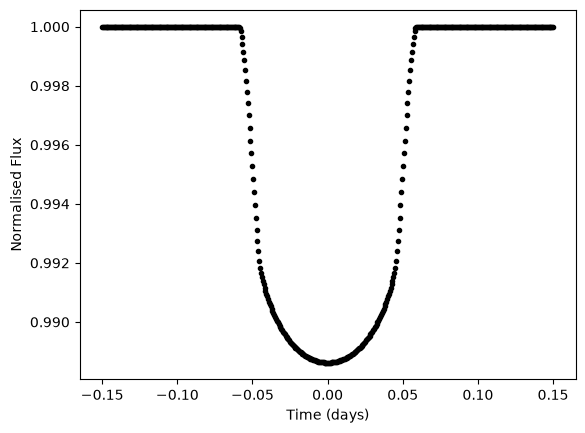

In [4]:
# Use some simple parameters typical of a hot Jupiter
mfp = {
    "T0":0.,     # Central transit time
    "P":3.,      # Period (days)
    "a":8.,      # Semi-major axis to stellar ratio aka a/R*
    "rho":0.1,   # Radius ratio rho aka Rp/R*
    "b":0.5,     # Impact parameter
    "u1":0.5,    # First quadratic limb darkening coefficient
    "u2":0.1,    # Second quadratic limb darkening coefficient
    "Foot":1.,   # Baseline flux out of transit
    "Tgrad":0.   # Gradient in baseline flux (hrs^-1)
}

# Generate 100 evenly spaced time points (in units of days)
N_t = 512
x_t = jnp.linspace(-0.15, 0.15, N_t)

plt.plot(x_t, transit_light_curve(mfp, x_t), "k.")
plt.xlabel("Time (days)")
plt.ylabel("Normalised Flux")
plt.show()

Now we want to take our ``jax`` function which has been written to generate a 1D light curve in time and instead create separate light curves in each wavelength. We also will want to share some parameters between light curves (e.g. impact parameter b, system scale a/Rs) while varying other parameters for each wavelength (e.g. radius ratio Rp/Rs).

We could of course write a ``for`` loop but for loops can be slow to compile with ``jax``. A more efficient option is to make use of the ``jax.vmap`` function which allows us to "vectorise" our function from 1D to 2D:

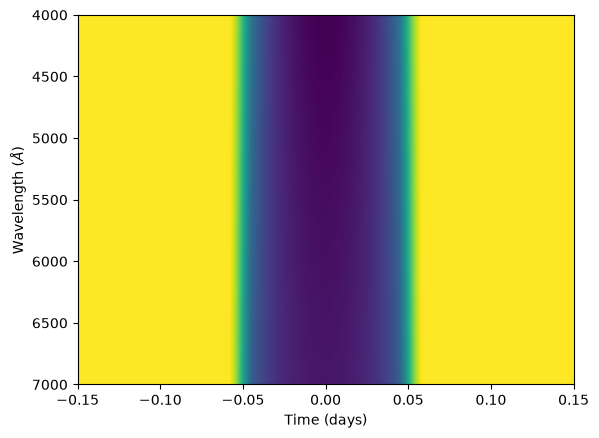

In [5]:
# First we must tell JAX which parameters of the function we want to vary for each light curve
# and which we want to be shared between light curves
transit_light_curve_vmap = jax.vmap(
    # First argument is the function to vectorise
    transit_light_curve, 
    
    # Specify which parameters to share and which to vary for each light curve
    in_axes=(
        {
        # If a parameter is to be shared across each light curve then it should be set to None
        "T0":None, "P":None, "a":None, "b":None,

        # Parameters which vary in wavelength are given the dimension of the array to expand along
        # In this case we are expanding from 0D arrays to 1D arrays so this must be 0
        "rho":0, "u1":0, "u2":0, "Foot":0, "Tgrad":0
        },
        # Also must specify that we will share the time array (the second function parameter)
        # between light curves
         None,  
    ),
    
    # Specify the output dimension to expand along, this will default to 0 anyway
    # Will output extra flux values for each light curve as additional rows
    out_axes = 0,
)

# Let's define a wavelength range of our data, this isn't actually used by our mean function
# but we will use it for defining correlation in wavelength later
N_l = 16 # Feel free to vary the number of light curves, even >100 light curves may perform quite efficiently
x_l = np.linspace(4000, 7000, N_l)

X = (x_l, x_t)

# Now we define our 2D transit parameters, let's just assume most parameters are constant in wavelength
# We are letting the limb darkening parameters vary linearly in wavelength, feel free to replace
# with generated limb-darkening parameters from a package of your choice
mfp_2D = {
    "T0":0.,                          # Central transit time
    "P":3.,                           # Period (days)
    "a":8.,                           # Semi-major axis to stellar ratio aka a/R*
    "rho":0.1*jnp.ones(N_l),          # Radius ratio rho aka Rp/R*
    "b":0.5,                          # Impact parameter
    "u1":jnp.linspace(0.7, 0.4, N_l), # First quadratic limb darkening coefficient
    "u2":jnp.linspace(0.1, 0.2, N_l), # Second quadratic limb darkening coefficient
    "Foot":1.*jnp.ones(N_l),          # Baseline flux out of transit
    "Tgrad":0.*jnp.ones(N_l)          # Gradient in baseline flux (days^-1)
}

# Call our new vmap of transit_light_curve to simultaneously compute light curves for all wavelengths
transit_model_2D = transit_light_curve_vmap(mfp_2D, x_t)

# Visualise the transit light curves
plt.imshow(transit_model_2D, aspect = 'auto', extent = [x_t[0], x_t[-1], x_l[-1], x_l[0]])
plt.xlabel("Time (days)")
plt.ylabel(r"Wavelength ($\AA$)")
plt.show()

The form of a mean function with ``luas.GP`` is ``f(par, X)`` where ``par`` is a PyTree, and ``X`` for 2D is a tuple of the input vectors for each dimension, in this case ``X = (x_l, x_t)`` where ``x_l`` is a JAXArray of inputs that lie along the wavelength/vertical dimension of the data (e.g. an array of wavelength values) and ``x_t`` is a JAXArray of inputs that lie along the time/horizontal dimension (e.g. an array of timestamps). Our transit model does not require wavelength values to be computed but we still write our wrapper function to be of this form.

We will also switch to the [Kipping (2013)](https://arxiv.org/abs/1308.0009) limb darkening parameterisation, but you can just remove this line and fit directly for `u1` and `u2` in your parameter dict if desired.

Also feel free to use the ``luas.exoplanet.transit_2D`` function instead which is similar to the below function with the exception that it fits for transit depth $d = \rho^2$ instead of radius ratio $\rho$

In [6]:
from luas.exoplanet import ld_to_kipping, ld_from_kipping

def transit_light_curve_2D(p, X):
    
    # vmap requires that we only input the parameters which have been explicitly defined how they vectorise
    transit_params = ["T0", "P", "a", "rho", "b", "Foot", "Tgrad"]
    mfp = {k:p[k] for k in transit_params}
    
    # Calculate limb darkening coefficients from the Kipping (2013) parameterisation.
    mfp["u1"], mfp["u2"] = ld_from_kipping(p["q1"], p["q2"])
    
    # Use the vmap of transit_light_curve to calculate a 2D array of shape (M, N) of flux values
    # For M wavelengths and N time points.
    return transit_light_curve_vmap(mfp, X[1])


# Switch to Kipping parameterisation
if "u1" in mfp_2D:
    mfp_2D["q1"], mfp_2D["q2"] = ld_to_kipping(mfp_2D["u1"], mfp_2D["u2"])
    del mfp_2D["u1"]
    del mfp_2D["u2"]

# This should produce the same result as transit_light_curve_vmap as we have only changed the limb darkening parameterisation
M = transit_light_curve_2D(mfp_2D, X)

Now that we have our mean function created, it's time to start building a kernel function. We will try keep things simple and use a squared exponential kernel for correlation in both time and wavelength, and white noise which varies in amplitude between different light curves.

$$
\begin{equation}
\mathbf{K}_{ij} = h^2 \exp\left(-\frac{|\lambda_i - \lambda_j|^2}{2 l_\mathrm{\lambda}^2}\right) \exp\left(-\frac{|t_i - t_j|^2}{2 l_{t}^2}\right) + \sigma_{\lambda_i}^2\delta_{\lambda_i \lambda_j} \delta_{t_i t_j}
\end{equation}
$$

This kernel contains a correlated noise component with height scale $h$, length scale in wavelength $l_\mathrm{\lambda}$ and length scale in time $l_t$. There is also a white noise term which can have different white noise amplitudes at different wavelengths.

We will need to write this kernel as separate wavelength and time kernel functions multiplied together satisfying:

$$
\begin{equation}
\text{K}(\Delta \lambda, \Delta t) = \text{K}_{l}(\Delta \lambda) \otimes \text{K}_{t}(\Delta t) + \text{S}_{l}(\Delta \lambda) \otimes \text{S}_{t}(\Delta t)
\end{equation}
$$

We can do this by choosing the equations below for our kernel functions which generate each component matrix.

$$
\begin{equation}
    \text{K}_l(\lambda_i, \lambda_j) = h^2 \exp\left(-\frac{|\lambda_i - \lambda_j|^2}{2 l_\mathrm{\lambda}^2}\right) 
\end{equation}
$$

$$
\begin{equation}
    \text{K}_t(t_i, t_j) = \exp\left(-\frac{|t_i - t_j|^2}{2 l_{t}^2}\right)
\end{equation}
$$

$$
\begin{equation}
    \text{S}_l(\lambda_i, \lambda_j) = \sigma_{\lambda_i}^2\delta_{\lambda_i \lambda_j}
\end{equation}
$$

$$
\begin{equation}
    \text{S}_t(t_i, t_j) = \delta_{t_i t_j}
\end{equation}
$$

Note that for numerical stability reasons it's important that the $S_l$ and $S_t$ matrices are well-conditioned (i.e. can be stably inverted) while $K_l$ and $K_t$ do not need to be well-conditioned (or even invertible), semi-positive definite matrices are okay for these. The matrices which contain values added along the diagonal should be well-conditioned as this "regularises" the matrices, while a squared exponential kernel with nothing added along the diagonal is unlikely to be well-conditioned.

In [7]:
import luas

# We implement each of these kernel functions below using the luas.kernels module
# for an implementation of the squared exponential kernel

# The wavelength kernel functions take the wavelength regression variable(s) x_l as input (of shape (N_l) or (d_l, N_l))
def build_kf(hp, X):

    Sl = luas.kernels.Noise(jnp.exp(hp["log_sigma"]))
    St = luas.kernels.KroneckerDelta()
    
    Kl = jnp.exp(2*hp["log_h"])*luas.kernels.SquaredExp(jnp.exp(hp["log_l_l"]))
    Kt = luas.kernels.quasisep.Exp(jnp.exp(hp["log_l_t"]))
    
    return (Sl, St), (Kl, Kt)
    
hp = {
    "log_h":np.log(2e-4),
    "log_l_l":np.log(1000.),
    "log_l_t":np.log(0.011),
    "log_sigma":np.log(5e-4)*np.ones(N_l),
}


gp = luas.GP(hp, X, mf = transit_light_curve_2D, kf = build_kf, use_kernel = luas.LuasLasrachKernel, fast_dim = 1)

Using: LuasLasrachKernel


The ``LuasKernel.visualise_covariance_matrix`` method should be a useful way of visualising each of the four component matrices and ensure everything you have written looks right. It uses ``matplotlib.pyplot.pcolormesh`` to visualise the covariance matrices which can produce weird looking plots for large matrices however.

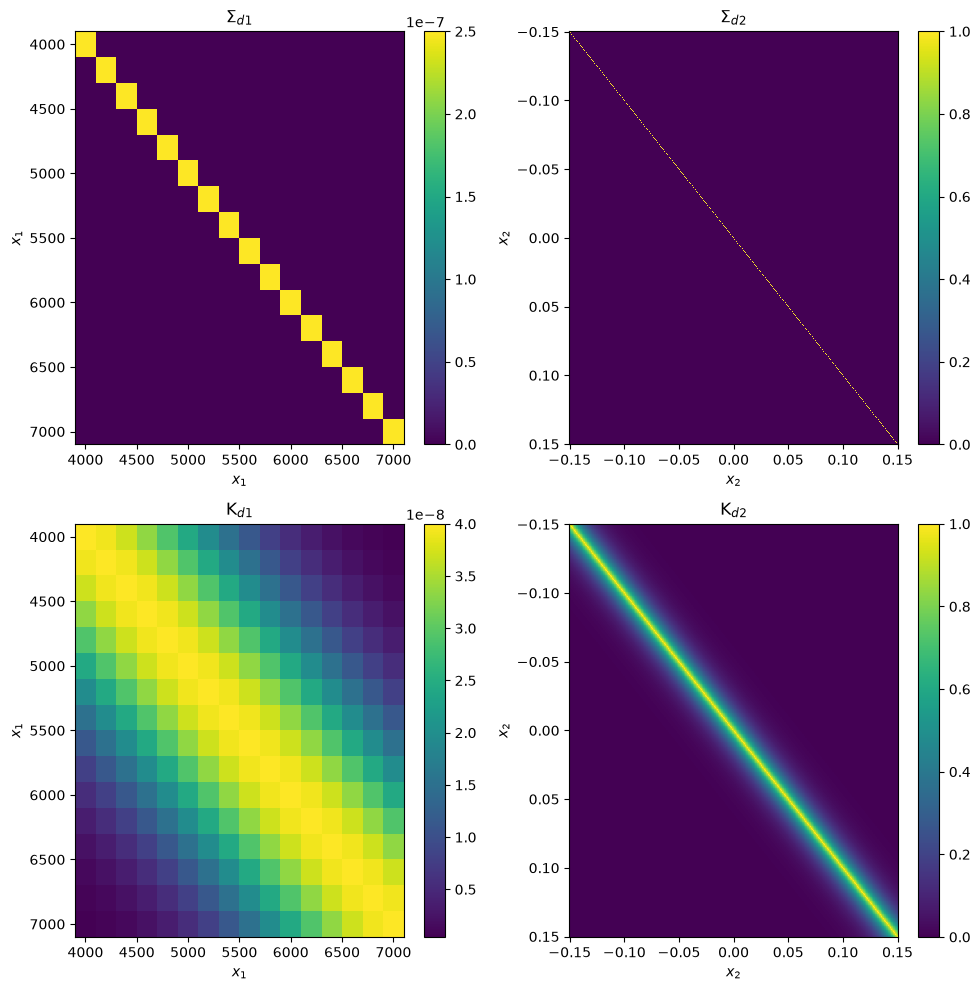

In [8]:
gp.plot_cov_mat(hp);

Take a random noise draw from this covariance matrix. Try playing around with these values to see the effect varying each parameter has on the noise generated.

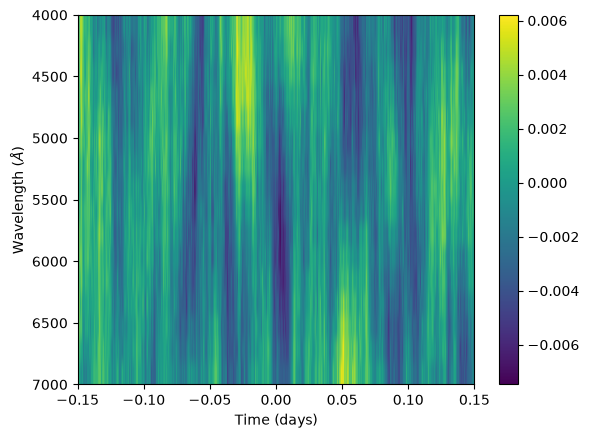

In [9]:
hp = {"log_h":jnp.log(2e-3),
      "log_l_l":jnp.log(1000.), 
      "log_l_t":jnp.log(0.011),
      "log_sigma":jnp.log(5e-4)*jnp.ones(N_l)}

sim_noise = gp.sample(hp, add_mf = False)

plt.imshow(sim_noise, aspect = 'auto', extent = [x_t[0], x_t[-1], x_l[-1], x_l[0]])
plt.xlabel("Time (days)")
plt.ylabel(r"Wavelength ($\AA$)")
plt.colorbar()
plt.show()

Combining our light curves and noise model we can generate synthetic light curves contaminated by systematics correlated in time and wavelength. We've added a gp.plot_lightcurves function to help visualise this. It also contains a convenient keyword argument ``bin`` which takes a tuple of ints you can bin each dimension by, useful if fitting a large number of lightcurves and binning the fits up in wavelength.

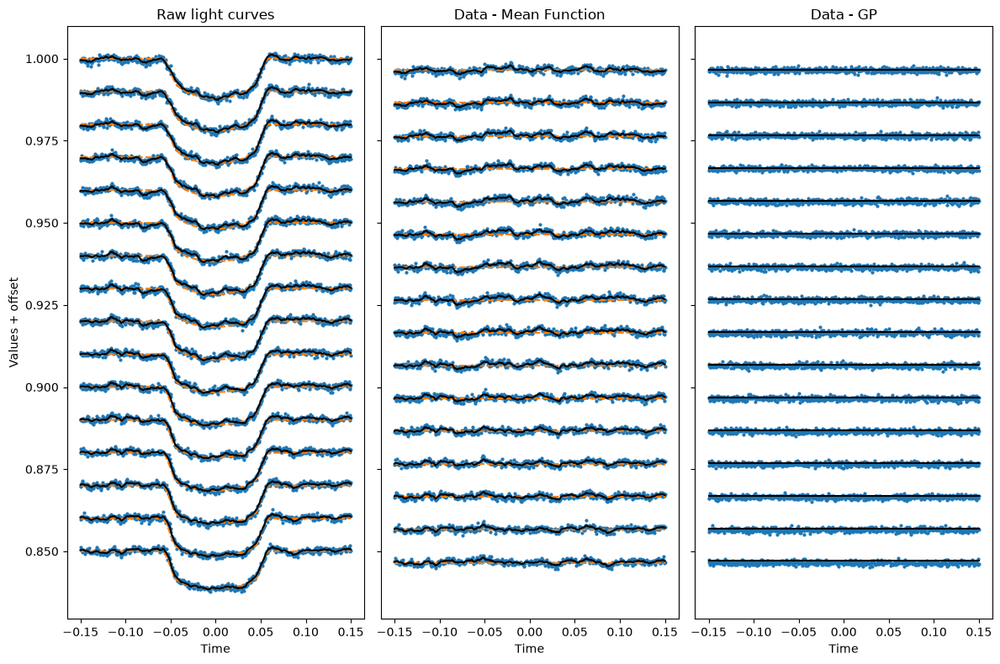

In [11]:
u1_sim, u2_sim = np.linspace(0.7, 0.4, N_l), np.linspace(0.1, 0.2, N_l)
q1_sim, q2_sim = ld_to_kipping(u1_sim, u2_sim)

# All parameters used to generate the synthetic data set with noise
# PyMC will not work with jax arrays as inputs so we are using NumPy arrays
# Our PyMC wrapper also assumes that each input is an array so convert floats to size 1 NumPy arrays
p_sim = {
    # Mean function parameters
    "T0":0.,                      # Central transit time
    "P":3.,                       # Period (days)
    "a":8.,                       # Semi-major axis to stellar ratio aka a/R*
    "rho":0.1*np.ones(N_l),                  # Radius ratio rho aka Rp/R* for each wavelength
    "b":0.5,                      # Impact parameter
    "q1":q1_sim,                             # First quadratic limb darkening coefficient for each wavelength
    "q2":q2_sim,                             # Second quadratic limb darkening coefficient for each wavelength
    "Foot":1.*np.ones(N_l),                  # Baseline flux out of transit for each wavelength
    "Tgrad":0.*np.ones(N_l),                 # Gradient in baseline flux for each wavelength (days^-1)
    
    # Hyperparameters
    "log_h":np.log(5e-4),        # log height scale
    "log_l_l":np.log(1000.),     # log length scale in wavelength
    "log_l_t":np.log(0.011),     # log length scale in time
    "log_sigma":np.log(5e-4)*np.ones(N_l),  # log white noise amplitude for each wavelength
}

transit_signal = transit_light_curve_2D(p_sim, X)
sim_noise = gp.sample(p_sim, add_mf = False)
Y = transit_signal*(1 + sim_noise)

gp.plot_lightcurves(p_sim, Y, bin = (1, 1), sep = 0.01);

We may also want to define a logPrior function. While PyMC can also be used to define priors on parameters, it can be useful to let ``luas.GP`` handle non-uniform priors when it comes to MCMC tuning (as will be shown later).

The ``logPrior`` function input to ``luas.GP`` should be written in JAX and must be of the form ``logPrior(params)`` i.e. it may only take the PyTree of mean function parameters and hyperparameters as input.

In [12]:
a_mean = p_sim["a"]
a_std = 0.1
b_mean = p_sim["b"]
b_std = 0.01

# Set some limb darkening priors, normally these might be generated from a package like LDTk
u1_mean = u1_sim
u1_std = 0.01
u2_mean = u2_sim
u2_std = 0.01

def logPrior(p, X):
    logPrior = luas.priors.Normal(p["a"], a_mean, a_std)
    logPrior += luas.priors.Normal(p["b"], b_mean, b_std)
    
    u1, u2 = ld_from_kipping(p["q1"], p["q2"])
    logPrior += luas.priors.Normal(u1, u1_mean, u1_std)
    logPrior += luas.priors.Normal(u2, u2_mean, u2_std)

    return logPrior.sum()

print("Log prior at simulated values:", logPrior(p_sim, X))

Log prior at simulated values: 123.02929110164217


We now have enough to define our ``luas.GP`` object and use it to try recover the original transmission signal injected into the correlated noise.

Using: LuasLasrachKernel
Starting log posterior value: 50292.92281950363


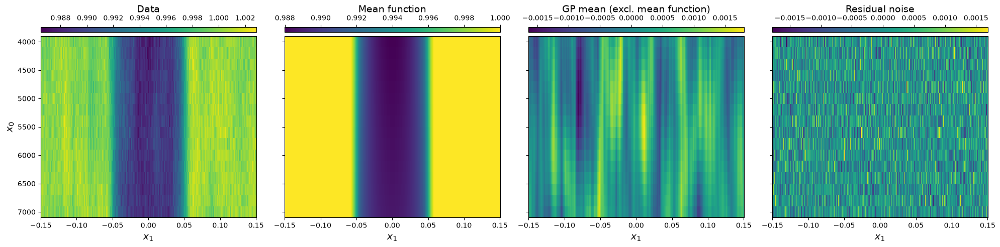

In [13]:
from copy import deepcopy

# Initialise our starting values as the true simulated values
p_initial = deepcopy(p_sim)

# Initialise our GP object
# Make sure to include the mean function and log prior function if you're using them
gp = luas.GP(p_initial,  # Kernel object to use
        X,     # Regression variable(s)
        mf = transit_light_curve_2D,  # (optional) mean function to use, defaults to zeros
        kf = build_kf,
        logPrior = logPrior,           # (optional) log prior function, defaults to zero
)

# Convenient function for plotting the data and the GP fit to the data
gp.plot(p_initial, Y)
print("Starting log posterior value:", gp.logP(p_initial, Y))

Measure runtimes to give a sense of GP cost and transit model cost:

In [14]:
gp.logP(p_initial, Y).block_until_ready()

print("Runtime with mean function:")
%timeit gp.logP(p_initial, Y).block_until_ready()
print("")

gp_no_mf = luas.GP(p_initial,  X, kf = build_kf, logPrior = logPrior, verbose = False)
gp_no_mf.logP(p_initial, Y).block_until_ready()

print("Runtime without mean function:")
%timeit gp_no_mf.logP(p_initial, Y).block_until_ready()

Runtime with mean function:
305 μs ± 16.7 μs per loop (mean ± std. dev. of 7 runs, 1,000 loops each)

Runtime without mean function:
114 μs ± 1.22 μs per loop (mean ± std. dev. of 7 runs, 10,000 loops each)


Now let's begin using PyMC to perform a best-fit. We've set the true simulated values as our initial values so we should already be close to the optimal log posterior value but for real data this won't always be the case. Similar to the approach in Fortune et al. (2024) we will not be performing any white light curve analysis but instead will be joint-fitting all spectroscopic light curves simultaneously.

Varying parameters: ['Foot', 'T0', 'Tgrad', 'a', 'b', 'log_h', 'log_l_l', 'log_l_t', 'log_sigma', 'q1', 'q2', 'rho']
Fixed parameters: ['P']


Output()

Starting log posterior value: 50292.92281950363
New optimised log posterior value: 50339.56102852535


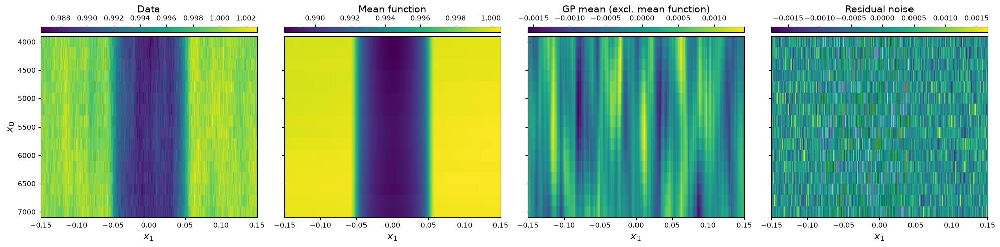

In [15]:
# Let's define some bounds
min_log_l_l = np.log(np.diff(x_l).min())
max_log_l_l = np.log(50*(x_l[-1] - x_l[0]))
min_log_l_t = np.log(np.diff(x_t).min())
max_log_l_t = np.log(3*(x_t[-1] - x_t[0]))

# Note with PyMC that the parameter bounds must also be NumPy arrays
param_bounds = {
                # Bounds from Kipping (2013) at just between 0 and 1
                "q1":[np.array([0.]*N_l), np.array([1.]*N_l)],
                "q2":[np.array([0.]*N_l), np.array([1.]*N_l)],
    
                # Can optionally include bounds on other mean function parameters
                # but often they will be well constrained by the data
                "rho":[np.array([0.]*N_l), np.array([1.]*N_l)],
    
                # Sometimes prior bounds on hyperparameters are important for sampling
                # However their choice can sometimes affect the results so use with caution
                "log_h":   [np.log(1e-6), np.log(1)],
                "log_l_l": [min_log_l_l, max_log_l_l],
                "log_l_t": [min_log_l_t, max_log_l_t],
                "log_sigma":[np.log(1e-6)*np.ones(N_l), np.log(1e-2)*np.ones(N_l)],
}

fixed_vars = ["P"]
p_opt = gp.optimise(p_initial, Y, fixed_vars = fixed_vars,
                    maxeval = 20000, tol = 1e-10, # you can play around with maxeval and tol to tune the best-fit
)

print("Starting log posterior value:", gp.logP(p_initial, Y))
print("New optimised log posterior value:", gp.logP(p_opt, Y))

gp.plot(p_opt, Y)

For NUTS sampling, it is often good to estimate the covariance matrix of the posterior first. luas provides support to do this by calculating a Laplace approximation, which uses the matrix of second derivatives (known as the Hessian) at the location of best-fit, and uses this measure of curvature to estimate the posterior covariance matrix. It will be most accurate when the best-fit is a good estimate of the maximum posterior value, if the parameters are well-behaved, not close to any priors bounds, and ideally have a close to linear effect on the model. Parameters which don't fit this might not be best sampled with NUTS, but for this tutorial we should be okay sampling them all like this.

In [ ]:
# Returns the covariance matrix returned by the Laplace approximation
# Also returns a list of parameters which is the order the array is in
# This matches the way jax.flatten_util.ravel_pytree will sort the parameter PyTree into
cov_mat, ordered_param_list = gp.laplace_approx_with_bounds(
    p_opt,                      # Make sure to use best-fit values
    Y,                          # The observations being fit
    param_bounds,               # Specify the same bounds that will be used for the MCMC
    fixed_vars = fixed_vars,    # Make sure to specify fixed parameters as otherwise they are marginalised over
    return_array = True,        # May optionally return a nested PyTree if set to False which can be more readable
    regularise_std = {},        # Often necessary to regularise values that return negative covariance
    large = False,              # Setting this to True breaks the calculation into batches which can be important
                                # as it is more memory efficient (and can be faster), which may be needed for large data sets
)

100%|██████████| 6/6 [00:02<00:00,  2.73it/s]


luas provides a helper function `gp.pymc_model` which will build and return a PyMC model, the variables of the model, and the starting values of just the parameters being varied. It assumes when building the model that all the parameters being varied have uniform priors within their parameterisation, but adds any priors placed on the parameters in the `logPrior` function, and puts uniform bounds on parameters specified in `param_bounds`.

PyMC appears to be unable to run JAX functions in parallel which is why ``cores = 1`` has been set. If wanting to run in parallel then the current suggestion is to run separate programs in parallel which each runs a chain with ``PyMC`` and save each ``arviz`` inference data object separately. These can later by loaded in and combined with ``arviz.concat``

In [17]:
import pymc as pm

# Initialise our PyMC model
pymc_model, var_dict, p_pymc = gp.pymc_model(p_opt, Y, param_bounds = param_bounds, fixed_vars = fixed_vars)

# The NUTS step takes as input the variables created when initialising the model
# We also sort these variables in the same order our Laplace approximated covariance matrix is in
NUTS_model_vars = [var_dict[par] for par in ordered_param_list]
NUTS_step = pm.NUTS(NUTS_model_vars, model = pymc_model, scaling = cov_mat, is_cov = True)

# Begin MCMC sampling
idata = pm.sample(
    model = pymc_model,           # PyMC model to sample
    step = NUTS_step,        # Sampling steps to use (can be list for blocked Gibbs sampling)
    initvals = p_pymc,          # Starting point of inference (will jitter around this location)
    draws = 1000,            # Number of samples from MCMC post warm-up
    tune = 1000,             # Number of tuning steps
    chains = 2,              # Number of chains to run
    cores = 1,               # This will probably fail if not set to 1 as I don't think PyMC can parallelise JAX functions
)


# convenient functions for saving posterior chains to a file and also reloading them
def save_posterior(idata, path):
    np.savez(path, **{name: np.asarray(val) for name, val in idata.posterior.data_vars.items()})

def load_posterior(path):
    # only works on arviz 1.x
    posterior = dict(np.load(path))
    return az.from_dict({"posterior": posterior})


Varying parameters: ['Foot', 'T0', 'Tgrad', 'a', 'b', 'log_h', 'log_l_l', 'log_l_t', 'log_sigma', 'q1', 'q2', 'rho']
Fixed parameters: ['P']


Sequential sampling (2 chains in 1 job)
NUTS: [Foot, T0, Tgrad, a, b, log_h, log_l_l, log_l_t, log_sigma, q1, q2, rho]


Output()

Sampling 2 chains for 1_000 tune and 1_000 draw iterations (2_000 + 2_000 draws total) took 68 seconds.
We recommend running at least 4 chains for robust computation of convergence diagnostics


We can instead build a NumPyro model and use its NUTS sampler, alternatively skip ahead to see the analysis of the chains using arviz

In [18]:
from numpyro.infer import MCMC, NUTS
from jax import random
from numpyro.infer.initialization import init_to_value

model = gp.numpyro_model(p_opt, Y, param_bounds = param_bounds, fixed_vars = ["P"])

# NumPyro makes use of the jax.random module to handle randomness
rng_key, rng_key_predict = random.split(random.PRNGKey(0))

# Define the sampler we will use
nuts_step = NUTS(model, # Our transit model specified earlier
                   init_strategy = init_to_value(values = p_opt), # Often works well to initialise near best-fit values
                   inverse_mass_matrix = cov_mat, # Inverse mass matrix is the same as the tuning covariance matrix
                   adapt_mass_matrix=False, # Often Laplace approximation works better than trying to tune many parameters
                   dense_mass = True,       # Need a dense mass matrix to account for correlations between parameters
                   regularize_mass_matrix = False, # Mass matrix should already be regularised
                  )

mcmc = MCMC(
    nuts_step,         # Sampler to use
    num_warmup=1000,   # Number of warm-up steps
    num_samples=1000,  # Number of samples post warm-up
    num_chains=2,      # Number of chains to run
)

# Run inference with given random seed and any arguments to the NumPyro model
mcmc.run(rng_key, Y)

# Generate an arviz inference data object from MCMC chains
idata = az.from_numpyro(mcmc)


# convenient functions for saving posterior chains to a file and also reloading them
def save_posterior(idata, path):
    np.savez(path, **{name: np.asarray(val) for name, val in idata.posterior.data_vars.items()})

def load_posterior(path):
    # only works on arviz 1.x
    posterior = dict(np.load(path))
    return az.from_dict({"posterior": posterior})

/var/folders/cn/hj79sjr57yq6wg9j0cwhf6s80000gn/T/ipykernel_9253/3463413415.py:19: UserWarning: There are not enough devices to run parallel chains: expected 2 but got 1. Chains will be drawn sequentially. If you are running MCMC in CPU, consider using `numpyro.set_host_device_count(2)` at the beginning of your program. You can double-check how many devices are available in your system using `jax.local_device_count()`.
  mcmc = MCMC(
sample: 100%|██████████| 2000/2000 [00:30<00:00, 65.25it/s, 7 steps of size 4.78e-01. acc. prob=0.83]


Print a summary of the samples using ``arviz``. Important values to look at for convergence are that the effective sample size of the bulk of the distribution (``ess_bulk``) and the tail of the distribution (``ess_tail``) are at least ~500-1000 and that the Gelman-Rubin ``r_hat`` statistic is less than ~1.01 for each parameter.

In [19]:
az.summary(idata, round_to = 6, ci_prob = 0.683)

,mean,sd,eti68_lb,eti68_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
Foot[0],0.999868,0.000204,0.999660,1.000065,1579.739483,1224.818054,1.000710,0.000005,0.000005
Foot[1],0.999916,0.000203,0.999716,1.000109,1755.828533,1243.469655,1.000280,0.000005,0.000005
Foot[2],0.999976,0.000203,0.999774,1.000174,1833.589174,1249.504367,1.000571,0.000005,0.000005
Foot[3],0.999936,0.000202,0.999741,1.000129,2093.048547,1338.978754,1.000252,0.000004,0.000005
Foot[4],1.000006,0.000204,0.999807,1.000196,2034.636614,1309.591952,0.999907,0.000005,0.000005
Foot[5],1.000049,0.000204,0.999847,1.000241,1880.519554,1304.466505,0.999906,0.000005,0.000005
Foot[6],1.000044,0.000205,0.999848,1.000243,1728.790718,1185.255536,1.001055,0.000005,0.000005
Foot[7],1.000157,0.000206,0.999961,1.000356,1630.164264,1009.941717,1.000903,0.000005,0.000006
Foot[8],1.000155,0.000205,0.999962,1.000353,1505.348474,1186.101643,1.000857,0.000005,0.000006
Foot[9],1.000226,0.000204,1.000029,1.000424,1434.968210,1265.649022,1.000555,0.000005,0.000006


The ``arviz.plot_trace`` function can be very useful for visualising the marginal posterior distributions of the different parameters as well as to examine the chains and diagnose any possible convergence issues.

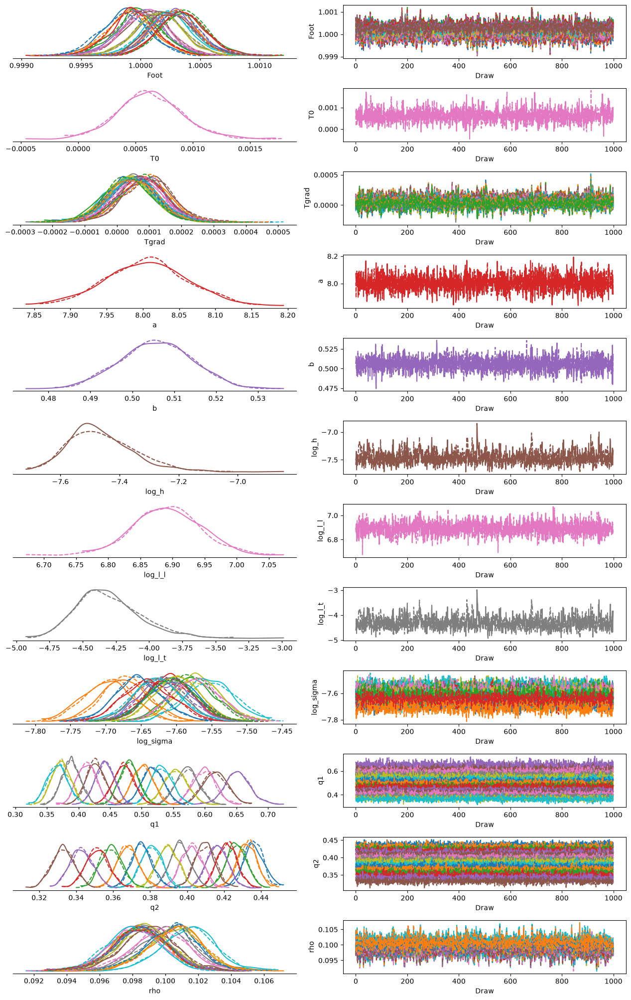

In [20]:
trace_plot = az.plot_trace_dist(idata)
plt.tight_layout()

``corner`` is great for generating nice corner plots. Unfortunately when fitting many light curves the number of parameters can make visualising the full corner plot quite unwieldly but we can always just plot subsets of parameters instead.

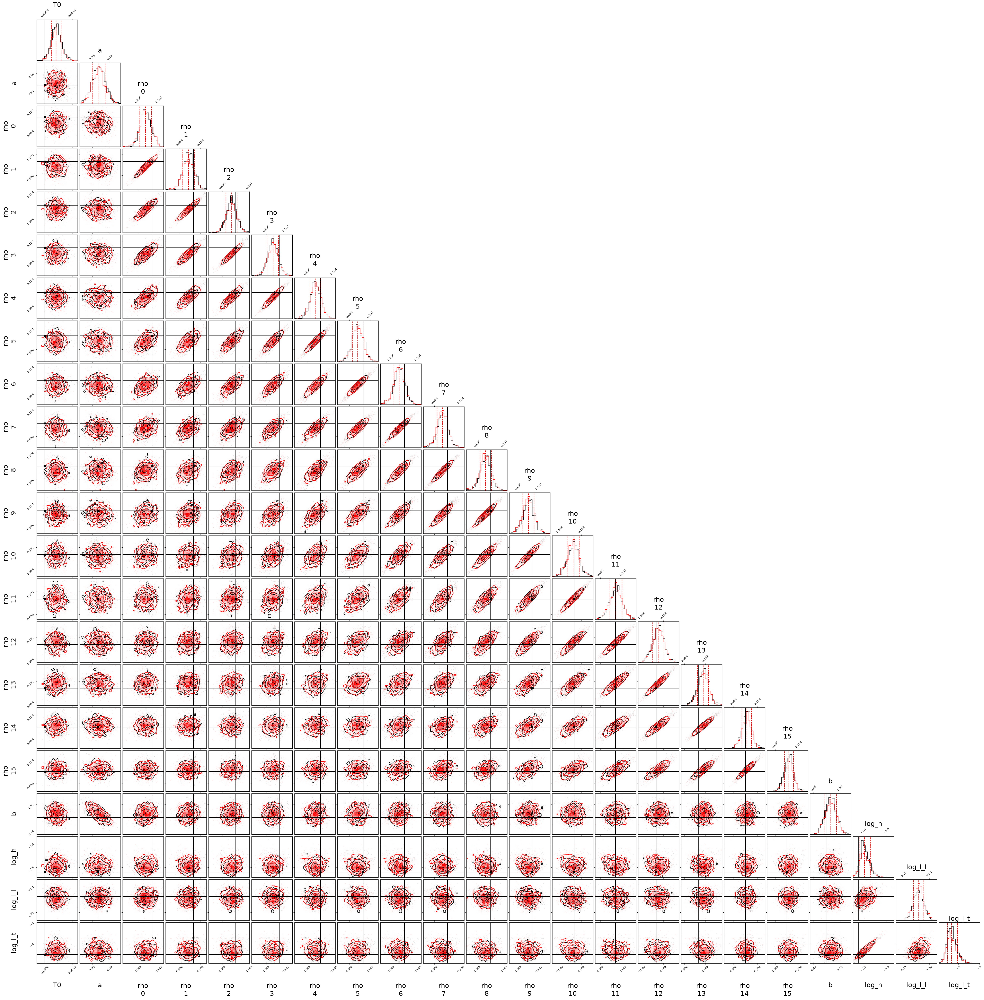

In [21]:
from corner import corner

# Select the parameters to include in the plot
params = ["T0", "a", "rho", "b", "log_h", "log_l_l", "log_l_t"]

# Plot each of the two chains separately
idata_corner1 = idata.sel(chain=[0])
idata_corner2 = idata.sel(chain=[1])

# Plot first chain
fig1 = corner(idata_corner1, smooth = 0.4, var_names = params)

# Plot second chain along with truth values
fig2 = corner(idata_corner2, quantiles=[0.16, 0.5, 0.84], title_fmt = None, title_kwargs={"fontsize": 23},
              label_kwargs={"fontsize": 23}, show_titles=True, smooth = 0.4, color = "r", fig = fig1,
              top_ticks = True, max_n_ticks = 2, labelpad = 0.16, var_names = params,
              truths = p_sim, truth_color = "k", dpi = 75,
              )

If you want to examine the chains for any parameters you can use ``idata.posterior[param]`` to get an ``xarray.DataArray`` object and can use the ``to_numpy`` method to convert to a ``NumPy`` array. Below we retrieve the mean and covariance matrix of the radius ratio parameters and then visualise the transmission spectrum as well as the covariance matrix of the transmission spectrum.

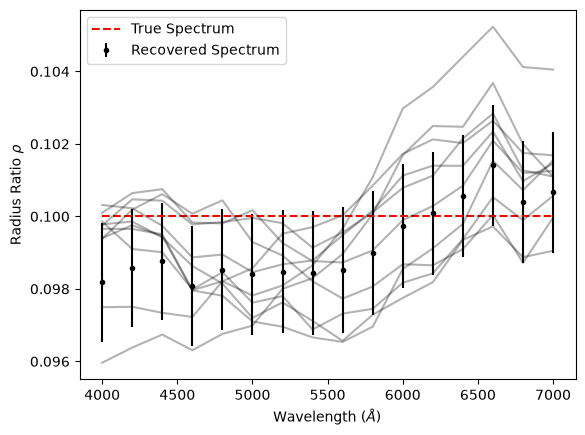

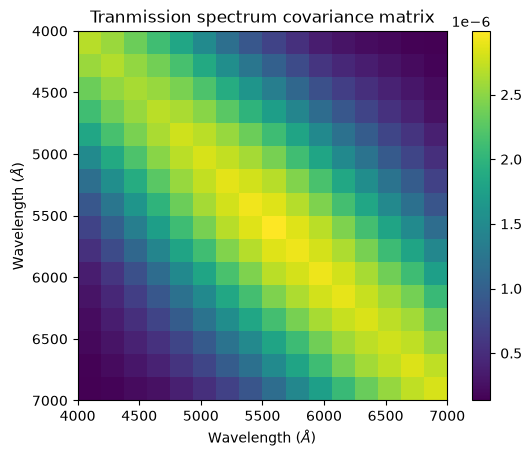

In [22]:
# NumPy array of MCMC samples of shape (N_chains, N_draws, N_l)
rho_chains = idata.posterior["rho"].to_numpy()

# Get the mean radius ratio values averaged over all chains and draws
rho_mean = rho_chains.mean((0, 1))

# Calculate the covariance matrix of each chain and average together
N_chains = rho_chains.shape[0]
rho_cov = jnp.zeros((N_l, N_l))
for i in range(N_chains):
    rho_cov += jnp.cov(rho_chains[i, :, :].T)
rho_cov /= N_chains

# Standard deviation given by sqrt of diagonal of covariance matrix
rho_std_dev = jnp.sqrt(jnp.diag(rho_cov))


# We can plot our recovered spectrum against the simulated true spectrum
plt.errorbar(x_l, rho_mean, yerr = rho_std_dev, fmt = 'k.', label = "Recovered Spectrum")
plt.plot(x_l, p_sim["rho"], 'r--', label = "True Spectrum")

# Select a few samples from the MCMC to help visualise the correlation between values
rho_draws = rho_chains[0, 0:1000:100, :].T
plt.plot(x_l, rho_draws, 'k-', alpha = 0.3)
plt.xlabel(r"Wavelength ($\AA$)")
plt.ylabel(r"Radius Ratio $\rho$")
plt.legend()
plt.show()

plt.title("Tranmission spectrum covariance matrix")
plt.imshow(rho_cov, extent = [x_l[0], x_l[-1], x_l[-1], x_l[0]])
plt.colorbar()
plt.xlabel(r"Wavelength ($\AA$)")
plt.ylabel(r"Wavelength ($\AA$)")
plt.show()

It can be hard to tell when there are significant correlations involved whether the recovered spectrum is actually consistent with the simulated spectrum. The reduced chi-squared statistic $\chi_r^2$ is useful for determining this. It is calculated using:

$$
\begin{equation}
    \chi_\mathrm{r}^2 = (\bar{\vec{\rho}}_\mathrm{ret} - \vec{\rho}_\mathrm{inj})^T \mathbf{K}_\mathrm{\vec{\rho}; ret}^{-1} (\bar{\vec{\rho}}_\mathrm{ret} - \vec{\rho}_\mathrm{inj}) / N_l,
\end{equation}
$$

Where $\bar{\vec{\rho}}_\mathrm{ret}$ is our retrieved mean transmission spectrum, $\vec{\rho}_\mathrm{inj}$ is the injected transmission spectrum and $\mathbf{K}_\mathrm{\vec{\rho}; ret}$ is our retrieved covariance matrix of the transmission spectrum.

In [23]:
r = rho_mean - p_sim["rho"]
chi2_r = r.T @ jnp.linalg.inv(rho_cov) @ r / N_l

print("Reduced chi-squared value:", chi2_r)

# The reduced chi-squared distribution always has mean 1 but has different standard deviations
# depending on the numbers of degrees of freedom
print("Distribution of reduced chi-squared: mean = 1, std. dev. =", jnp.sqrt(2/N_l))

Reduced chi-squared value: 1.5379671407550113
Distribution of reduced chi-squared: mean = 1, std. dev. = 0.3535533905932738
